<a href="https://colab.research.google.com/github/tougheye/geo_mapping/blob/main/UPTE_Member_Congressional_Dist_Mapping.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In this project, we upload the legislative district shape files (zip file) and the UPTE data files, merge them into one dataframe and map the data points accordingly.

In [ ]:
import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt

distr_data = gpd.read_file("/content/districts119.zip" )
distr_data['DISTRICT'] = distr_data['DISTRICT'].astype(int)
# distr_data[['STATENAME','DISTRICT']].head(100)

In [ ]:
upte_cnt_df = pd.read_csv("/content/UPTE_congressional_summary.csv", dtype={'DISTRICT': int, 'UPTE BU Cnt': int, 'Zip Code':str})
# upte_cnt_df.head()

In [ ]:
upte_cnt_shape_df = distr_data.merge(upte_cnt_df[['UPTE BU Cnt','Congressional District','DISTRICT', 'STATENAME']], on = ['DISTRICT', 'STATENAME'], how='left')
upte_cnt_shape_df = upte_cnt_shape_df.dropna(subset=['UPTE BU Cnt'])
# upte_cnt_shape_df.head()

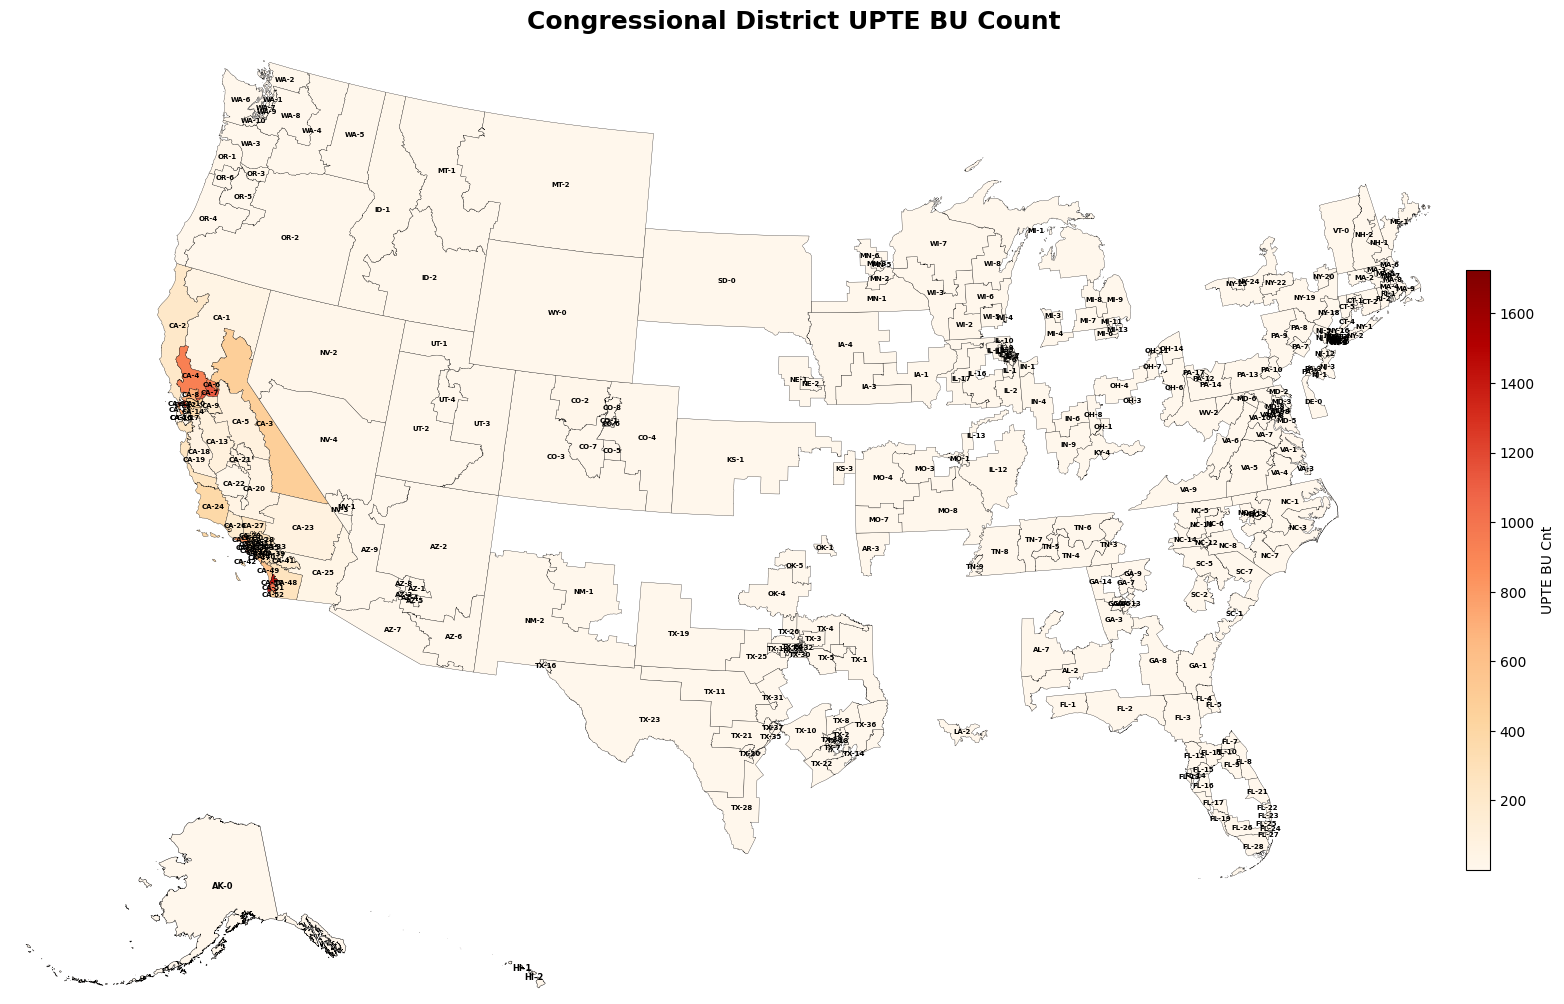

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import FancyArrowPatch
import geopandas as gpd
import numpy as np

# ── 1. Reproject everything to Albers Equal Area ──────────────────────────────
upte_cnt_shape_df = upte_cnt_shape_df.to_crs("ESRI:102003")

# ── 2. Split into mainland / Alaska / Hawaii ──────────────────────────────────
ak = upte_cnt_shape_df[upte_cnt_shape_df['Congressional District'].str.startswith('AK')]
hi = upte_cnt_shape_df[upte_cnt_shape_df['Congressional District'].str.startswith('HI')]
mainland = upte_cnt_shape_df[
    ~upte_cnt_shape_df['Congressional District'].str.startswith(('AK', 'HI'))
]

# Reproject Alaska & Hawaii to their own local CRS for cleaner insets
ak = ak.to_crs("EPSG:3338")   # Alaska Albers
hi = hi.to_crs("EPSG:4135")   # Hawaii

# ── 3. Build figure with inset axes ──────────────────────────────────────────
fig = plt.figure(figsize=(16, 10))

# Main axis — mainland
ax_main = fig.add_axes([0, 0.1, 1, 0.9])          # [left, bottom, width, height]

# Inset axes — bottom-left, standard US map style
ax_ak = fig.add_axes([0.01, 0.01, 0.22, 0.22])    # Alaska inset
ax_hi = fig.add_axes([0.23, 0.01, 0.12, 0.12])    # Hawaii inset

# ── 4. Color scale: shared across all three panels ───────────────────────────
col = 'UPTE BU Cnt'
vmin = upte_cnt_shape_df[col].min()
vmax = upte_cnt_shape_df[col].max()
cmap = 'OrRd'

# ── 5. Plot mainland ──────────────────────────────────────────────────────────
mainland.plot(ax=ax_main, column=col, cmap=cmap, vmin=vmin, vmax=vmax,
              edgecolor='black', linewidth=0.2, legend=False)

# Labels for mainland — centroid-based
for _, row in mainland.iterrows():
    centroid = row.geometry.centroid
    ax_main.annotate(
        text=row['Congressional District'],
        xy=(centroid.x, centroid.y),
        ha='center', va='center',
        fontsize=5, color='black',
        fontweight='bold',
        clip_on=True
    )

# ── 6. Plot Alaska inset ──────────────────────────────────────────────────────
ak.plot(ax=ax_ak, column=col, cmap=cmap, vmin=vmin, vmax=vmax,
        edgecolor='black', linewidth=0.3, legend=False)

for _, row in ak.iterrows():
    centroid = row.geometry.centroid
    ax_ak.annotate(
        text=row['Congressional District'],
        xy=(centroid.x, centroid.y),
        ha='center', va='center',
        fontsize=6, color='black', fontweight='bold',
        clip_on=True
    )

# ── 7. Plot Hawaii inset ──────────────────────────────────────────────────────
hi.plot(ax=ax_hi, column=col, cmap=cmap, vmin=vmin, vmax=vmax,
        edgecolor='black', linewidth=0.3, legend=False)

for _, row in hi.iterrows():
    centroid = row.geometry.centroid
    ax_hi.annotate(
        text=row['Congressional District'],
        xy=(centroid.x, centroid.y),
        ha='center', va='center',
        fontsize=6, color='black', fontweight='bold',
        clip_on=True
    )

# ── 8. Remove axis ticks & spines from ALL panels ────────────────────────────
for ax in [ax_main, ax_ak, ax_hi]:
    ax.set_axis_off()

# ── 9. Shared colorbar ────────────────────────────────────────────────────────
sm = plt.cm.ScalarMappable(cmap=cmap, norm=plt.Normalize(vmin=vmin, vmax=vmax))
sm.set_array([])
cbar_ax = fig.add_axes([0.92, 0.15, 0.015, 0.6])   # right side
fig.colorbar(sm, cax=cbar_ax, label='UPTE BU Cnt')

plt.suptitle('Congressional District UPTE BU Count', fontsize=18, fontweight='bold', y=1.01)
plt.savefig('upte_map.png', dpi=150, bbox_inches='tight')
plt.show()


Draw a California specific map for the congressional districts

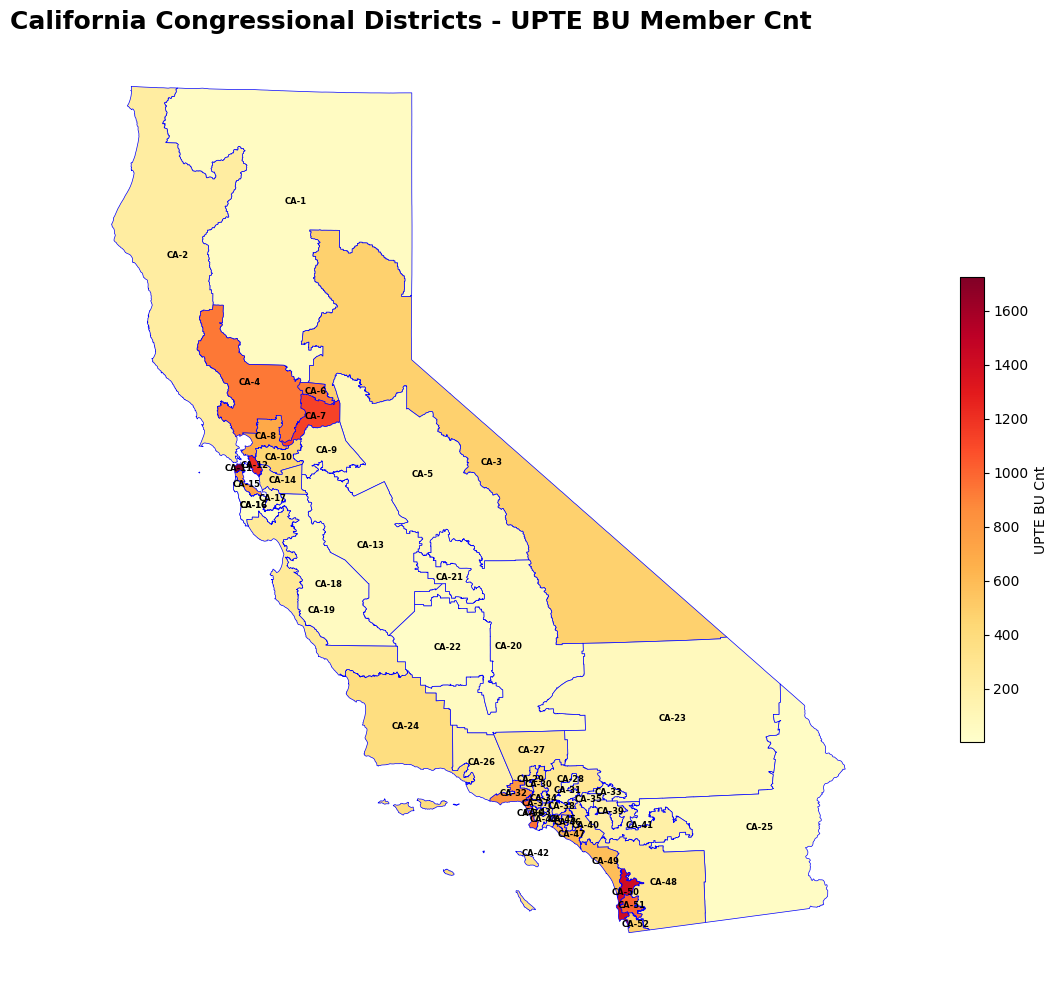

In [ ]:
ca_df = upte_cnt_shape_df[upte_cnt_shape_df['Congressional District'].str.startswith('CA')]

# reproject to California Albers
ca_df = ca_df.to_crs("EPSG:3310")

# create a California specific figure
fig_ca, ax_ca = plt.subplots(figsize=(16, 10))

# setup the color scale
col = 'UPTE BU Cnt'
vmin = ca_df[col].min()
vmax = ca_df[col].max()
cmap = 'YlOrRd'


# ── Plot California members ──────────────────────────────────────────────────────────
ca_df.plot(ax=ax_ca, column=col, cmap=cmap, vmin=vmin, vmax=vmax,
              edgecolor='blue', linewidth=0.5, legend=True,
           legend_kwds={'label': 'UPTE BU Cnt', 'shrink': 0.5})

# Labels for CA — centroid-based
for _, row in ca_df.iterrows():
    centroid = row.geometry.centroid
    ax_ca.annotate(
        text=row['Congressional District'],
        xy=(centroid.x, centroid.y),
        ha='center', va='center',
        fontsize=6, color='black',
        fontweight='bold',
        clip_on=True
    )

ax_ca.set_axis_off()

plt.suptitle('California Congressional Districts - UPTE BU Member Cnt',
             fontsize=18, fontweight='bold')
plt.tight_layout()
plt.savefig('upte_ca_map.png', dpi=150, bbox_inches='tight')
plt.show()

To be able to better visualize the high population districts, need to add the regional distinctions first and then create insets for each region

In [ ]:
# create regional distinctions - 2025 districts - https://sdmg.senate.ca.gov/committeehome/2025-congressional-districts
regional_dict = {"Northern and Sierra": [1, 3, 5],
                 "SF Bay and Greater Sacramento": [2 , 4, 6, 7, 8, 9, 10, 11, 12, 15, 14, 16, 17],
                 "Central Valley and High Desert": [13, 20, 21, 22, 23, 25],
                 "Central Coast": [18, 19, 24],
                 "SoCal - Greater LA, OC, IE": [26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47],
                 "SoCal - Greater SD": [ 48, 49, 50, 51, 52]}

In [ ]:
import pandas as pd
ca_cong_reg_df = pd.Series(regional_dict).explode().reset_index()
ca_cong_reg_df.columns = [ 'Region' , 'Congressional District']
# ca_cong_reg_df.head()

NameError: name 'regional_dict' is not defined

Merge the regional distribution data into the California data to be able to create insets for particularly populas areas

In [ ]:
ca_df_w_region = ca_df.merge(ca_cong_reg_df, left_on='DISTRICT',right_on='Congressional District', how='left').drop(columns=['Congressional District_y'])


In [ ]:
region_list = ca_df_w_region['Region'].unique()


NameError: name 'ca_df_w_region' is not defined

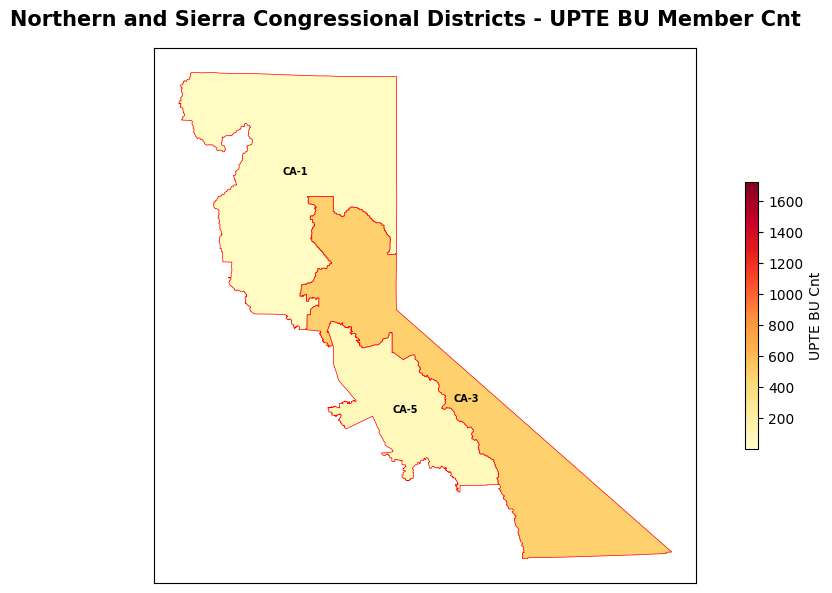

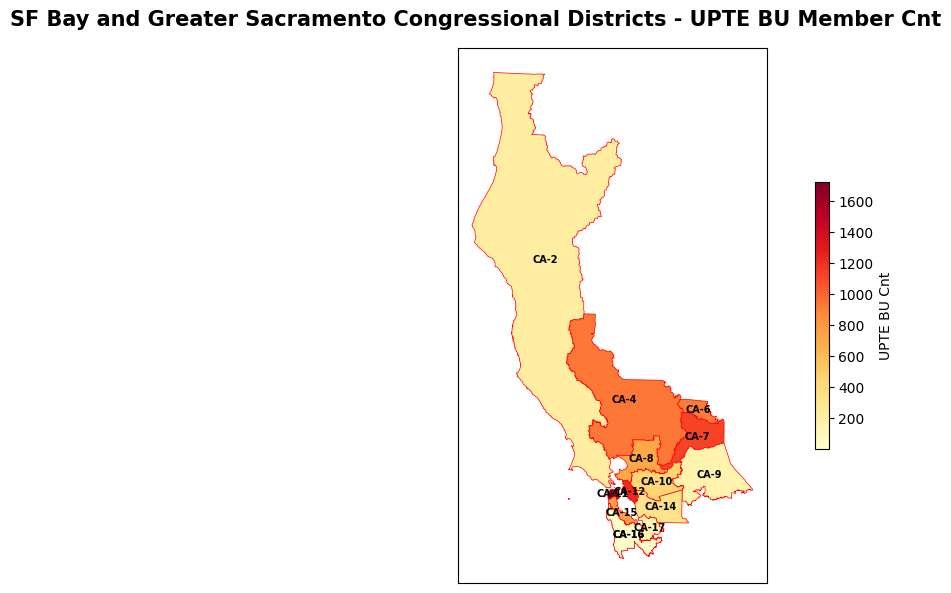

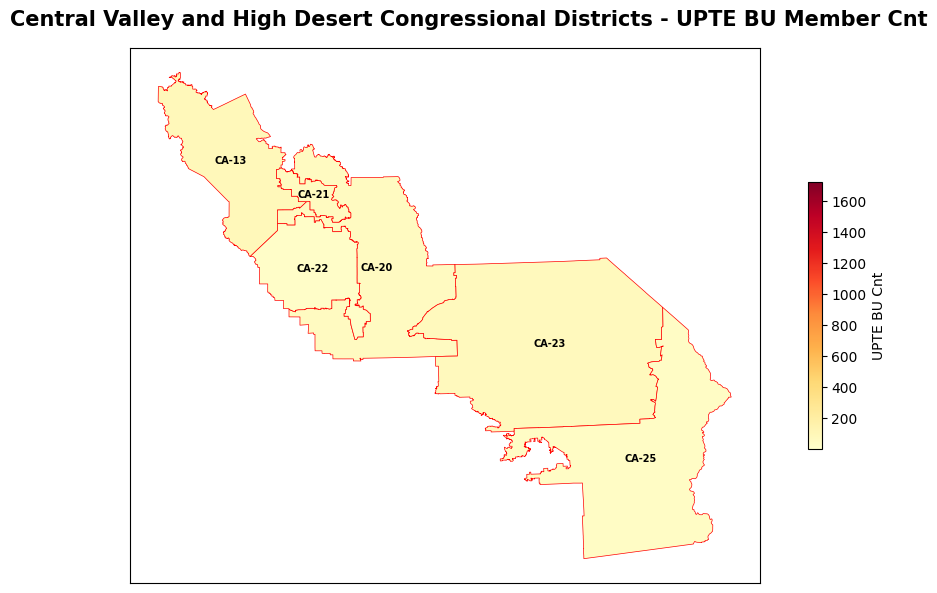

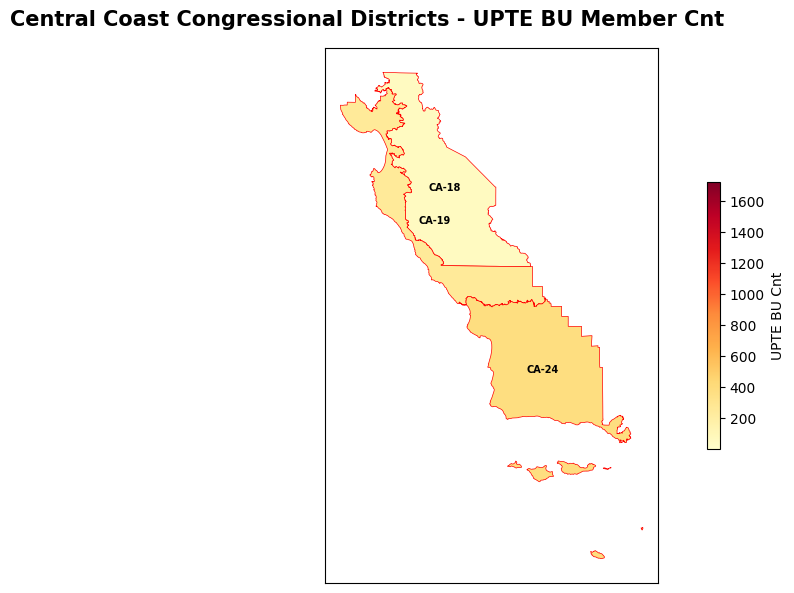

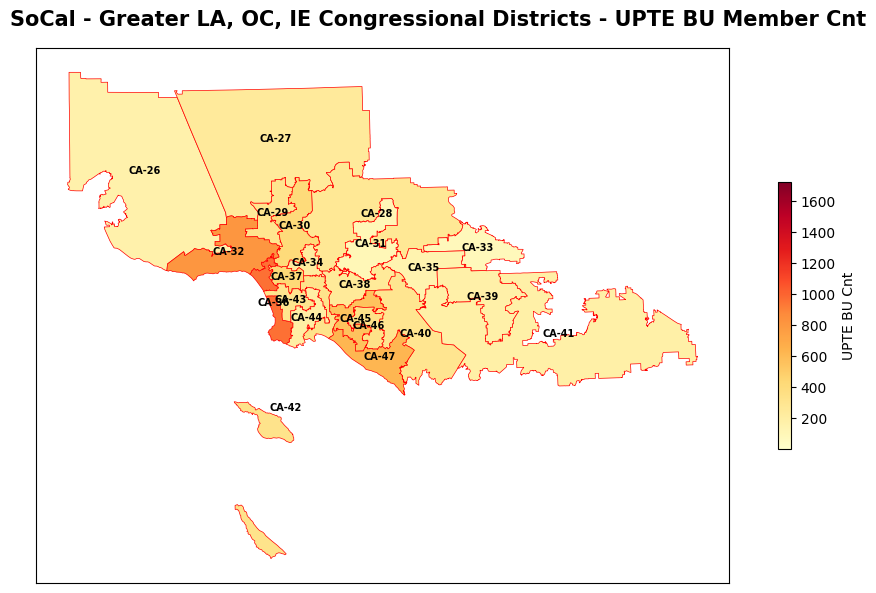

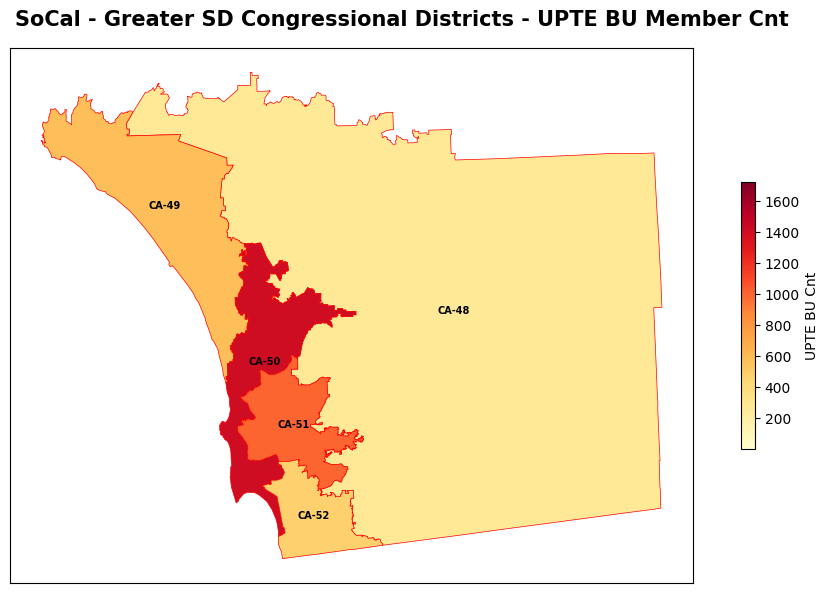

In [ ]:
for region in region_list:
  region_df = ca_df_w_region[ca_df_w_region['Region'] == region]

  # reproject to regional Albers
  region_df = region_df.to_crs("EPSG:3310")

  # create a region specific figure
  fig_region, ax_region = plt.subplots(figsize=(10, 6))

  # setup the color scale
  col = 'UPTE BU Cnt'
  vmin = ca_df[col].min()
  vmax = ca_df[col].max()
  cmap = 'YlOrRd'


  # ── Plot region's members ──────────────────────────────────────────────────────────
  region_df.plot(ax=ax_region, column=col, cmap=cmap, vmin=vmin, vmax=vmax,
                edgecolor='red', linewidth=0.5, legend=True,
            legend_kwds={'label': 'UPTE BU Cnt', 'shrink': 0.5})

  # Labels for regions — centroid-based
  for _, row in region_df.iterrows():
      centroid = row.geometry.centroid
      ax_region.annotate(
          text=row['Congressional District_x'],
          xy=(centroid.x, centroid.y),
          ha='center', va='center',
          fontsize=7, color='black',
          fontweight='bold',
          clip_on=True
      )

  ax_region.tick_params(left=False, bottom=False, labelleft=False, labelbottom=False)

  plt.suptitle(f'{region} Congressional Districts - UPTE BU Member Cnt',
              fontsize=15, fontweight='bold')
  plt.tight_layout()
  plt.savefig(f'{region}_upte_ca_map.png', dpi=150, bbox_inches='tight')
  plt.show()

# print("Done printing all inset maps")